# Baseline: bit-flip bee search for the 0-1 knapsack problem

A first, simpler bee-inspired method, kept as a baseline for the discrete ABC (`abc_knapsack.ipynb`).

Each bee holds a binary vector $x$. In every iteration $t$ the employed bees flip each bit with probability
$$p(t) = \delta \left(1 - \frac{t}{t_{\max}}\right)^{\eta}$$
and keep the neighbour only if it is strictly better. The search starts from **random** solutions and infeasible solutions receive a profit of 0.

In [1]:
import sys
from pathlib import Path

# Allow running the notebook without `pip install -e .`
sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bee_knapsack import P08, F2, F8, load_pisinger, make_bee, parameter_sweep, convergence_runs, plot_convergence, relative_error

## 1. Small instances

In [2]:
for inst in (P08, F2, F8):
    bee = make_bee(inst, max_iter=1000, delta=0.5, eta=0.9, seed=42)
    bee.run()
    print(f"{inst.name}: profit = {bee.best_profit:,.0f} (optimum {inst.optimum:,}), "
          f"gap = {relative_error(bee.best_profit, inst.optimum):.3f} %")

P08: profit = 13,466,838 (optimum 13,549,094), gap = 0.607 %
f2: profit = 1,024 (optimum 1,024), gap = 0.000 %
f8: profit = 9,767 (optimum 9,767), gap = 0.000 %


## 2. Parameter study on P08

Each pair $(\eta, \delta)$ is evaluated over 10 independent runs.

In [3]:
pd.DataFrame(parameter_sweep(P08, etas=[0.8, 0.9, 1.0], deltas=[0.4, 0.5, 1.0], runs=10)).round(3)

,eta,delta,mean,best,hit_rate,gap_%
0,0.9,0.5,13506454.1,13549094.0,0.1,0.315
1,1.0,0.4,13493845.1,13524340.0,0.0,0.408
2,0.8,0.4,13490293.9,13549094.0,0.1,0.434
3,0.8,0.5,13488968.6,13549094.0,0.1,0.444
4,0.9,0.4,13487090.5,13524340.0,0.0,0.458
5,1.0,0.5,13476805.8,13524340.0,0.0,0.534
6,0.9,1.0,13446033.1,13518963.0,0.0,0.761
7,0.8,1.0,13441270.8,13489043.0,0.0,0.796
8,1.0,1.0,13441044.0,13496748.0,0.0,0.797


The differences between settings are of the same order as the run-to-run variation, and the optimum of P08 is reached only occasionally (the discrete ABC reaches it in every run).

## 3. Convergence on P08

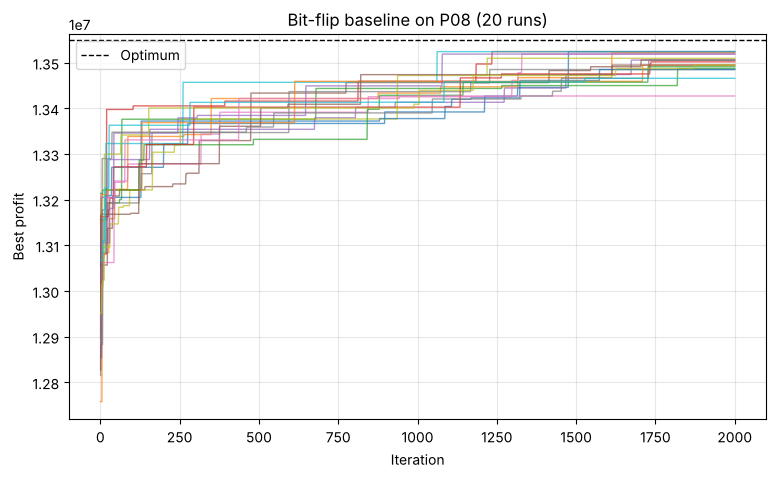

In [4]:
curves = convergence_runs(P08, runs=20, method="bitflip", max_iter=2000)
plot_convergence(curves, optimum=P08.optimum, title="Bit-flip baseline on P08 (20 runs)")
plt.show()

## 4. Failure on sparse instances

On PI_1_100 the optimal solution packs only 12 of 100 items. A random initial vector packs about half of the items and is therefore almost surely infeasible, so every bee starts with profit 0. Since a neighbour is accepted only if it is strictly better, and random neighbours are infeasible as well, the search never leaves the infeasible region.

In [5]:
inst = load_pisinger("PI_1_100")
bee = make_bee(inst, max_iter=1000, ns=500, nb=250, seed=0)
bee.run()
print(f"profit = {bee.best_profit:,.0f}  (optimum {inst.optimum:,})")

profit = 0  (optimum 9,147)


This motivates the two key ingredients of the discrete ABC: a **greedy initialisation** based on $v_i/w_i$, which starts from a good feasible solution, and a **repair step** that keeps every trial feasible.